In [19]:
import kagglehub

# Download latest version
# path = kagglehub.competition_download('titanic')

# print("Path to competition files: ", path)

# path = kagglehub.dataset_download("mirichoi0218/insurance")

# print("Path to dataset files:", path)


# Download latest version
# path = kagglehub.dataset_download("shivamb/netflix-shows")

# print("Path to dataset files:", path)

# path = kagglehub.dataset_download("unsdsn/world-happiness")

# print("Path to dataset files:", path)

# Download latest version
path = kagglehub.dataset_download("rtatman/188-million-us-wildfires")

print("Path to dataset files:", path)

Using Colab cache for faster access to the '188-million-us-wildfires' dataset.
Path to dataset files: /kaggle/input/188-million-us-wildfires


Size of train datasets: (891, 12)
Type of each parameter of dataset:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object
Describe dataset:
        PassengerId    Survived      Pclass                 Name   Sex  \
count    891.000000  891.000000  891.000000                  891   891   
unique          NaN         NaN         NaN                  891     2   
top             NaN         NaN         NaN  Dooley, Mr. Patrick  male   
freq            NaN         NaN         NaN                    1   577   
mean     446.000000    0.383838    2.308642                  NaN   NaN   
std      257.353842    0.486592    0.836071                  NaN   NaN   
min        1.000000    0.000000    1.000000                  NaN   NaN   
25%      223.500000    0.000000

/tmp/ipykernel_589/4127398603.py:55: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data= trainDS, x='Pclass', y='Survived', hue='Sex', ax=axes[0, 0], ci=None, palette='Set2')
/tmp/ipykernel_589/4127398603.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data= trainDS, x='Pclass', y='Fare', ax=axes[1, 0], palette='Set3')
/tmp/ipykernel_589/4127398603.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=trainDS, x='Survived', y='Age', ax=axes[1, 1], palette='Pastel1')
/tmp/ipykernel_589/4127398603.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedL

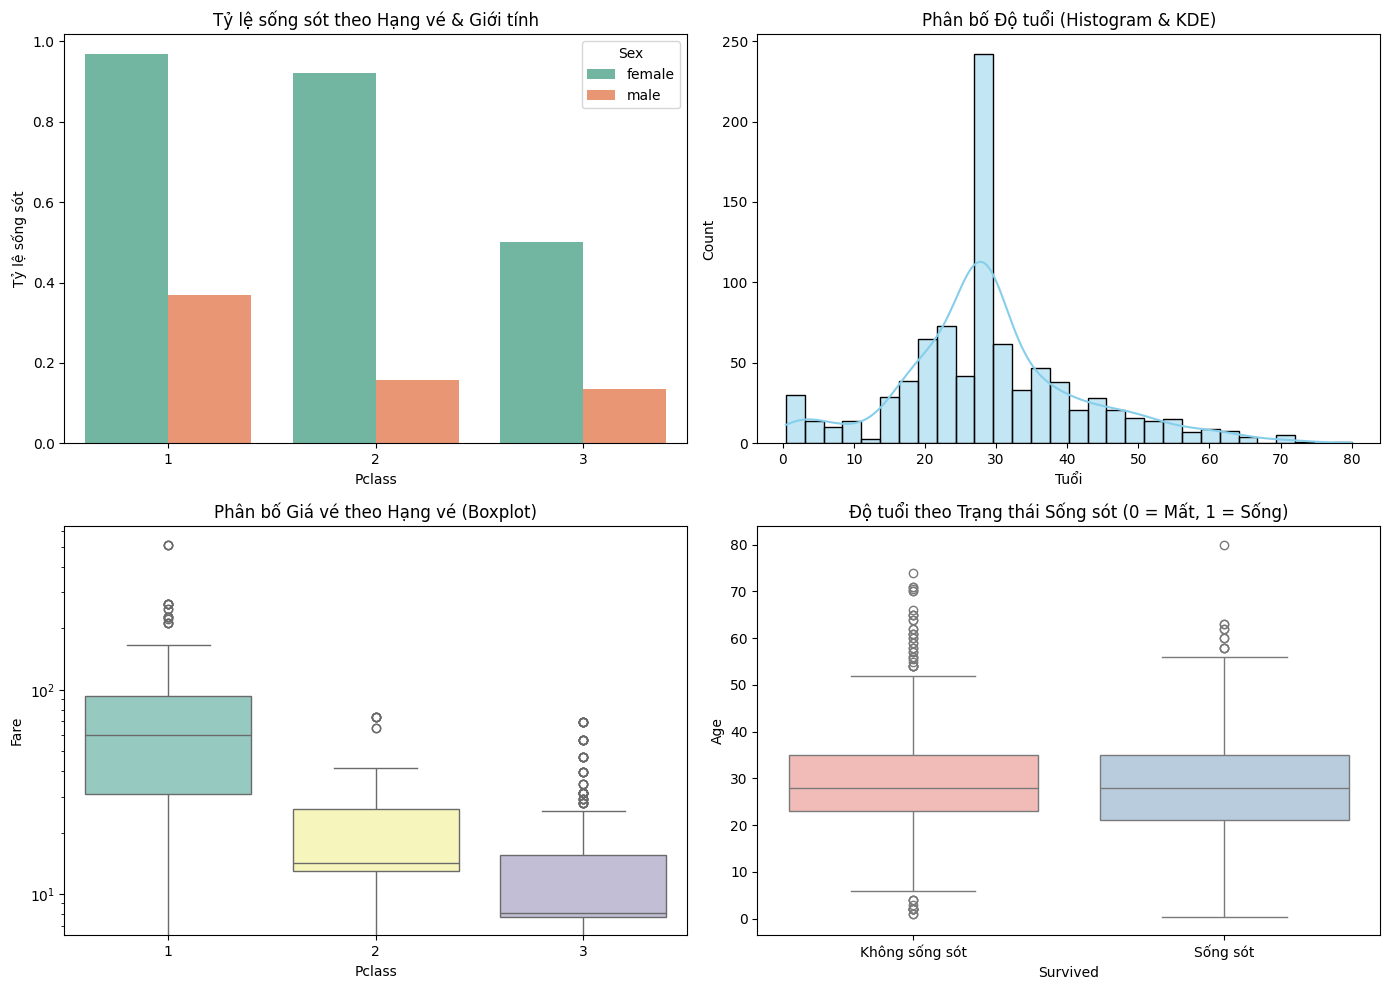

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = '/root/.cache/kagglehub/competitions/titanic'
#Đọc CSV, xem kích thước, kiểu dữ liệu và thống kê mô tả.
trainDS = pd.read_csv(f'{path}/train.csv')

print('Size of train datasets: ' + str(trainDS.shape))
print('Type of each parameter of dataset:')
print(trainDS.dtypes)
print('Describe dataset:')
print(trainDS.describe(include = 'all'))

#Xử lý giá trị thiếu.

print("Total missing value of each parameter before processing:")
print(trainDS.isnull().sum())

trainDS['Age'] = trainDS['Age'].fillna(trainDS['Age'].median())
trainDS['Embarked'] = trainDS['Embarked'].fillna(trainDS['Embarked'].mode()[0])
trainDS.drop(columns = ['Cabin'], inplace = True)

print("Total missing value of each parameter after processing:")
print(trainDS.isnull().sum())

#So sánh tỷ lệ sống sót theo giới tính và hạng vé.
print("Average survival rate by Sex:")
print(trainDS.groupby(['Sex'])['Survived'].mean().round(2))
print("Average survival rate by Pclass:")
print(trainDS.groupby(['Pclass'])['Survived'].mean().round(2))
print("Average survival rate by both Sex and Pclass:")
print(trainDS.groupby(['Pclass', 'Sex'])['Survived'].mean().round(2))

#Dùng NumPy tính trung bình, trung vị, độ lệch chuẩn.

ageDS = trainDS['Age'].to_numpy()
print(f'Average age:         {np.mean(ageDS):.2f}')
print(f'Median:              {np.median(ageDS):.2f}')
print(f'Standard deviation:  {np.std(ageDS):.2f}')

FareDS = trainDS['Fare'].to_numpy()

print(f'Average fare:        {np.mean(FareDS):.2f}')
print(f'Median:              {np.median(FareDS):.2f}')
print(f'Standard deviation:  {np.std(FareDS):.2f}')


#Vẽ biểu đồ cột, histogram và boxplot.

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Biểu đồ 1: Biểu đồ cột - Tỷ lệ sống sót theo Giới tính và Hạng vé
sns.barplot(data = trainDS, x='Pclass', y='Survived', hue='Sex', ax=axes[0, 0], ci=None, palette='Set2')
axes[0, 0].set_title('Tỷ lệ sống sót theo Hạng vé & Giới tính')
axes[0, 0].set_ylabel('Tỷ lệ sống sót')

# Biểu đồ 2: Histogram - Phân bố độ tuổi
sns.histplot(data= trainDS, x='Age', bins=30, kde=True, ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('Phân bố Độ tuổi (Histogram & KDE)')
axes[0, 1].set_xlabel('Tuổi')

# Biểu đồ 3: Boxplot - Phân bố Giá vé theo Hạng vé
sns.boxplot(data= trainDS, x='Pclass', y='Fare', ax=axes[1, 0], palette='Set3')
axes[1, 0].set_title('Phân bố Giá vé theo Hạng vé (Boxplot)')
axes[1, 0].set_yscale('log') # Dùng thang log do Giá vé có ngoại lệ (outliers) lớn

# Biểu đồ 4: Boxplot - Phân bố Độ tuổi theo Trạng thái Sống sót
sns.boxplot(data=trainDS, x='Survived', y='Age', ax=axes[1, 1], palette='Pastel1')
axes[1, 1].set_title('Độ tuổi theo Trạng thái Sống sót (0 = Mất, 1 = Sống)')
axes[1, 1].set_xticklabels(['Không sống sót', 'Sống sót'])

plt.tight_layout()
plt.show()

Tong so gia tri trung lap:
1
Du lieu trung lap:
     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631
Tong so gia tri thieu:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Kieu du lieu:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object
Chi phi:
                              mean       median
age sex    region                              
18  female northeast   4864.611121   2211.13075
           southeast   7903.630250   1634.26760
    male   northeast   9935.898417   3481.86800
           southeast   5516.011946   1163.46270
19  female northwest  10275.707652   2710.82855
...                            ...          ...
64  female southwest  36512.705333  47291.05500
    male   northeast  1440

/tmp/ipykernel_1209/1906872196.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = trainDS, x = 'region', y = 'charges', ax = axes[1, 0], palette = 'Set3')


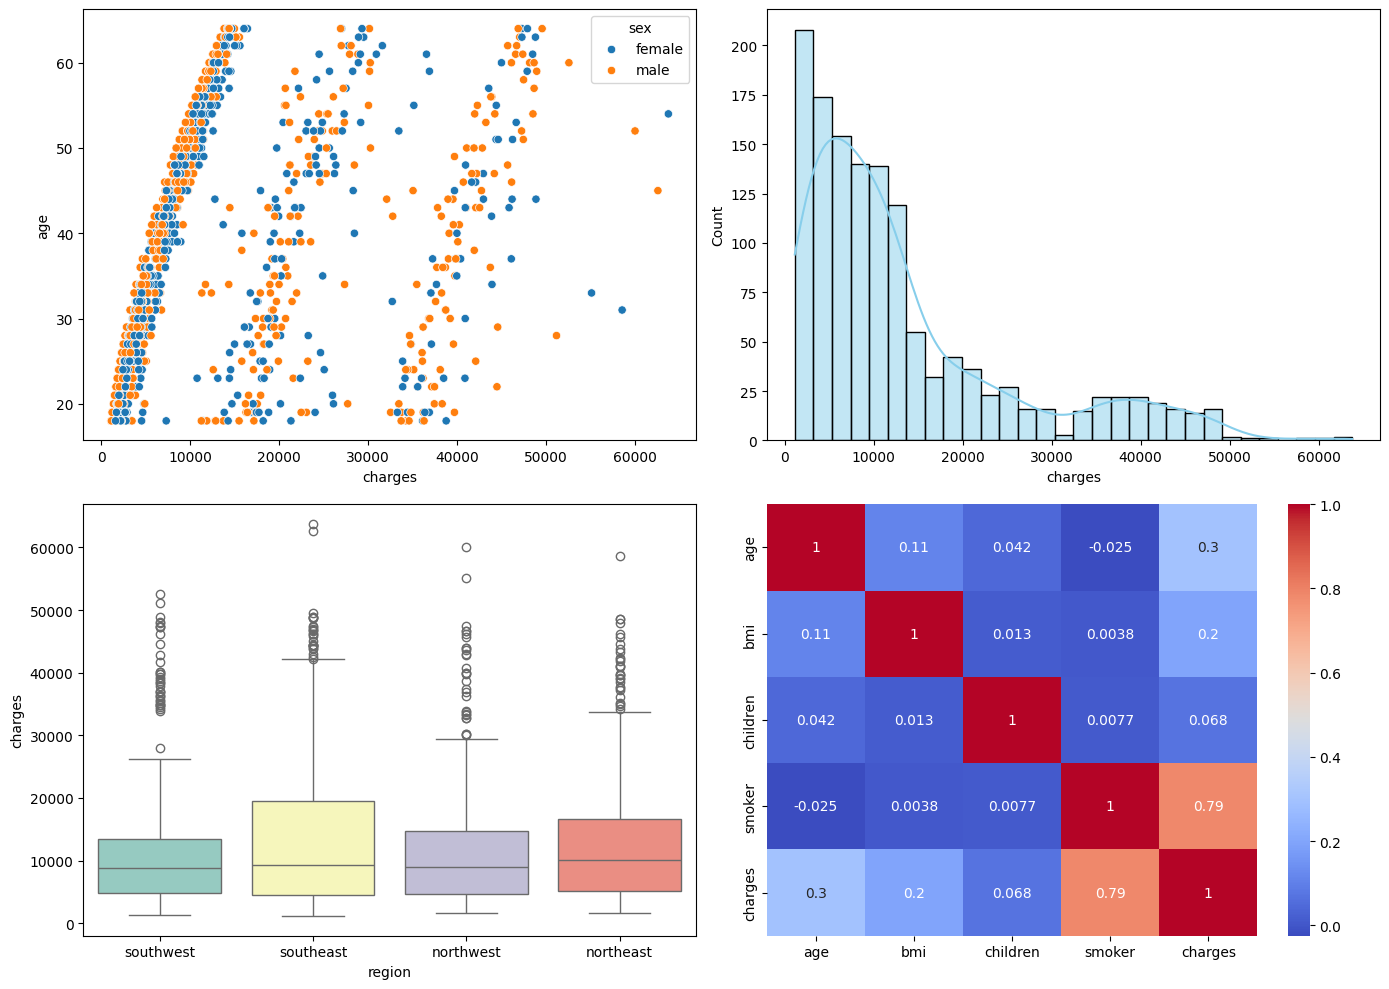

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = '/kaggle/input/insurance'
trainDS = pd.read_csv(f'{path}/insurance.csv')

#Kiểm tra dữ liệu trùng lặp, giá trị thiếu và kiểu dữ liệu.
print('Tong so gia tri trung lap:')
print(trainDS.duplicated().sum())
print('Du lieu trung lap:')
print(trainDS[trainDS.duplicated(keep = False)])
print('Tong so gia tri thieu:')
print(trainDS.isnull().sum())
print('Kieu du lieu:')
print(trainDS.dtypes)

#So sánh chi phí theo tuổi, giới tính, khu vực và tình trạng hút thuốc.

print('Chi phi:')
print(trainDS.groupby(['age', 'sex', 'region'])['charges'].agg(['mean','median']))
print('Chi phi theo tuoi:')
print(trainDS.groupby(['age'])['charges'].agg(['mean','median']))
print('Chi phi theo khu vuc :')
print(trainDS.groupby(['region'])['charges'].agg(['mean','median']))
print('Chi phi theo gioi tinh:')
print(trainDS.groupby(['sex'])['charges'].agg(['mean','median']))
# print(trainDS.pivot_table(index = 'age', columns = 'sex',values = 'charges', aggfunc = 'mean'))

trainDS['smoker'] = (trainDS['smoker'] == 'yes').astype(int)

print('Tinh trang hut thuoc:')
print(trainDS.groupby(['age', 'sex', 'region'])['smoker'].agg(['mean']))
print('Tinh trang hut thuoc theo tuoi:')
print(trainDS.groupby(['age'])['smoker'].agg(['mean']))
print('Tinh trang hut thuoc theo khu vuc:')
print(trainDS.groupby(['region'])['smoker'].agg(['mean']))
print('Tinh trang hut thuoc theo gioi tinh:')
print(trainDS.groupby(['sex'])['smoker'].agg(['mean']))


#Dùng NumPy tính phân vị và phát hiện các giá trị chi phí bất thường.

chargesDS = trainDS['charges'].to_numpy()

print('Phan vi:')
print(np.quantile(chargesDS, [0.25, 0.5, 0.75]))
print('Cac gia tri bat thuong:')
print(chargesDS[(chargesDS < np.quantile(chargesDS, 0.25) - 1.5 * np.std(chargesDS)) | (chargesDS > np.quantile(chargesDS, 0.75) + 1.5 * np.std(chargesDS))])

#Vẽ scatterplot, histogram, boxplot và heatmap tương quan.

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(data = trainDS, x = 'charges', y = 'age', hue = 'sex', ax = axes[0, 0], palette = 'Set2')

sns.histplot(data = trainDS, x = 'charges', bins = 30, kde = True, ax = axes[0, 1], color = 'skyblue')

sns.boxplot(data = trainDS, x = 'region', y = 'charges', ax = axes[1, 0], palette = 'Set3')

sns.heatmap(trainDS.corr(numeric_only = True), annot = True, cmap = 'coolwarm', ax = axes[1, 1])
plt.tight_layout()
plt.show()

      Action & Adventure  Anime Features  Anime Series  British TV Shows  \
0                  False           False         False             False   
1                  False           False         False             False   
2                  False           False         False             False   
3                  False           False         False             False   
4                  False           False         False             False   
...                  ...             ...           ...               ...   
8802                True           False         False             False   
8803               False           False         False             False   
8804               False           False         False             False   
8805               False           False         False             False   
8806               False           False         False             False   

      Children & Family Movies  Classic & Cult TV  Classic Movies  Comedies  \
0       

Text(0, 0.5, 'Số lượng nội dung')

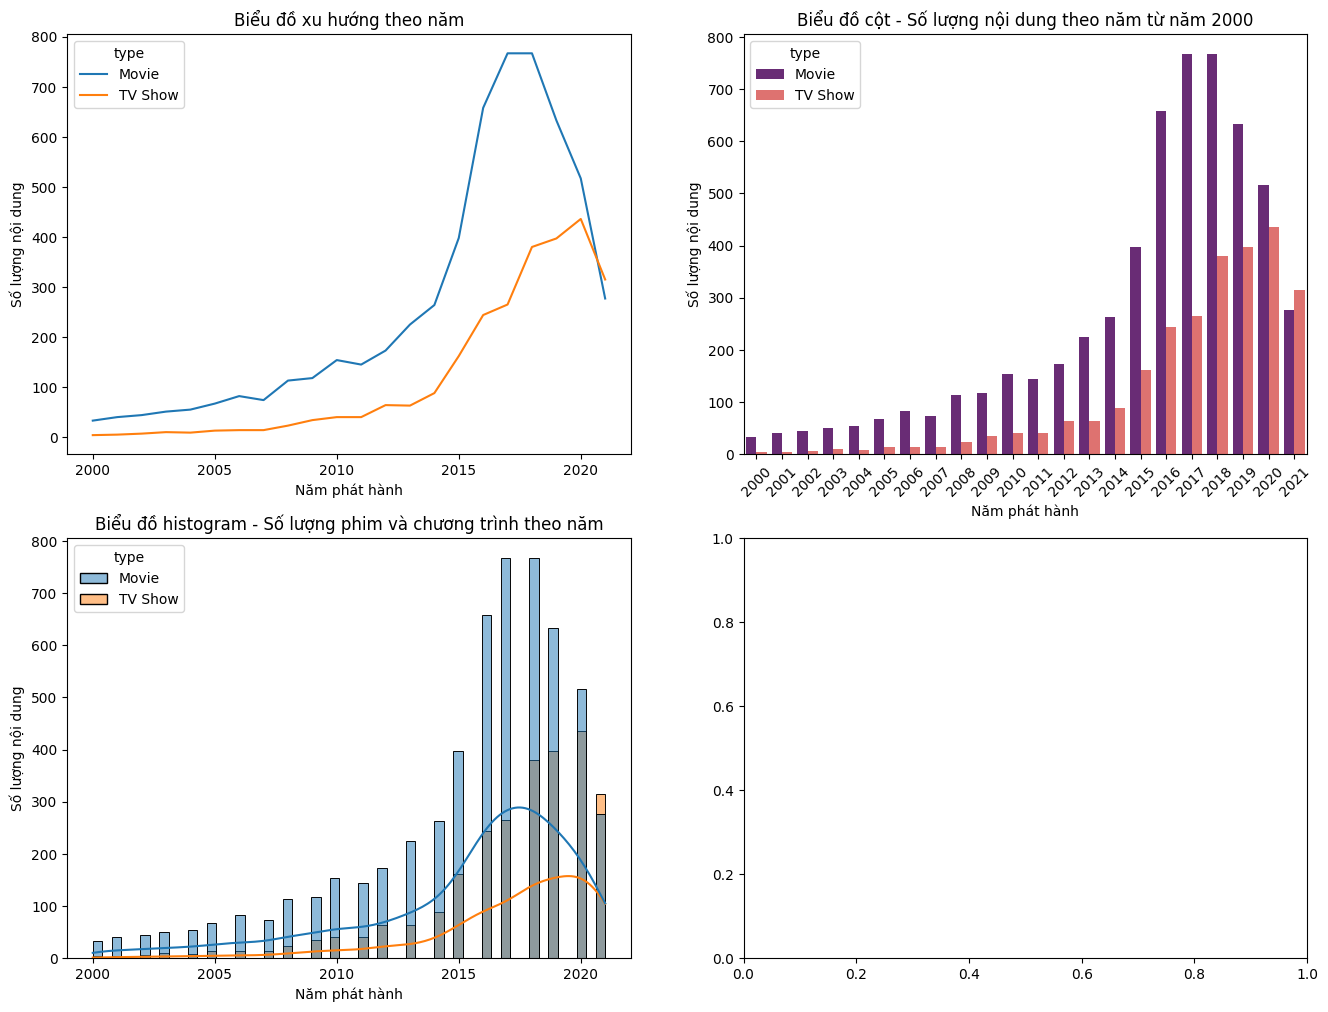

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
path = '/kaggle/input/netflix-shows'
trainDS = pd.read_csv(f'{path}/netflix_titles.csv')

#Xử lý dữ liệu thiếu ở director, cast, country.

trainDS['director'] = trainDS['director'].fillna('Unknown')
trainDS['cast'] = trainDS['cast'].fillna('Unknown')
trainDS['country'] = trainDS['country'].fillna('Unknown')
#Tách và chuẩn hóa cột thể loại, quốc gia.

trainDS['listed_in'] = trainDS['listed_in'].str.split(', ').explode('listed_in')
trainDS['country'] = trainDS['country'].str.split(', ').explode('country')

df_dummy = pd.get_dummies(trainDS['listed_in'])
trainDS = pd.concat([trainDS, df_dummy], axis = 1)
print(df_dummy)
print(trainDS['country'])

#Đếm số phim và chương trình theo năm, quốc gia, thể loại.

print('So phim theo nam, quoc gia, the loai:')
print(trainDS.groupby(['release_year','country','listed_in'])['title'].count())
print('So phim theo nam:')
print(trainDS.groupby(['release_year'])['title'].count())
print('So phim theo quoc gia:')
print(trainDS.groupby(['country'])['title'].count())
print('So phim theo the loai:')
print(trainDS.groupby(['listed_in'])['title'].count())

#So sánh phân bố thời lượng phim và số mùa chương trình.

movies_df = trainDS[trainDS['type'] == 'Movie']
tvshows_df = trainDS[trainDS['type'] == 'TV Show']

#Dien lai du lieu bi loi
missing_mask = movies_df['duration'].isnull()
movies_df.loc[missing_mask, 'duration'] = movies_df.loc[missing_mask, 'rating']

print('Phan bo thoi luong phim:')
print(movies_df['duration'].str.replace(' min', '').astype(int).describe())

print('Phan bo so mua chuong trinh:')
print(tvshows_df['duration'].str.split().str[0].astype(int).describe())

#Vẽ biểu đồ xu hướng theo năm, biểu đồ cột và histogram.

count_by_year = trainDS[trainDS['release_year'] >= 2000].groupby(['release_year', 'type']).size().reset_index(name='count')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.lineplot(data = count_by_year, x = 'release_year', y = 'count', hue = 'type', ax = axes[0, 0])
axes[0,0].set_title('Biểu đồ xu hướng theo năm')
axes[0, 0].set_xlabel('Năm phát hành')
axes[0, 0].set_ylabel('Số lượng nội dung')

sns.barplot(data = count_by_year, x = 'release_year', y = 'count', hue = 'type', ax = axes[0, 1], palette = 'magma')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].set_title('Biểu đồ cột - Số lượng nội dung theo năm từ năm 2000')
axes[0, 1].set_xlabel('Năm phát hành')
axes[0, 1].set_ylabel('Số lượng nội dung')

sns.histplot(data = trainDS[trainDS['release_year'] >= 2000], x = 'release_year', kde = True, hue = 'type', ax = axes[1,0])
axes[1, 0].set_title('Biểu đồ histogram - Số lượng phim và chương trình theo năm')
axes[1, 0].set_xlabel('Năm phát hành')
axes[1, 0].set_ylabel('Số lượng nội dung')


Diem hanh phuc theo quoc gia:
             Happiness Score
Country                     
Afghanistan            3.575
Albania                4.959
Algeria                5.605
Angola                 4.033
Argentina              6.574
...                      ...
Venezuela              6.810
Vietnam                5.360
Yemen                  4.077
Zambia                 5.129
Zimbabwe               4.610

[158 rows x 1 columns]
Diem hanh phuc theo khu vuc:
                                 Happiness Score
Region                                          
Australia and New Zealand               7.285000
Central and Eastern Europe              5.332931
Eastern Asia                            5.626167
Latin America and Caribbean             6.144682
Middle East and Northern Africa         5.406900
North America                           7.273000
Southeastern Asia                       5.317444
Southern Asia                           4.580857
Sub-Saharan Africa                      4.202800
W

/tmp/ipykernel_2321/2056203636.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = df.head(10), x = 'Happiness Score', y = 'Country', ax = axes[2], palette = 'viridis')


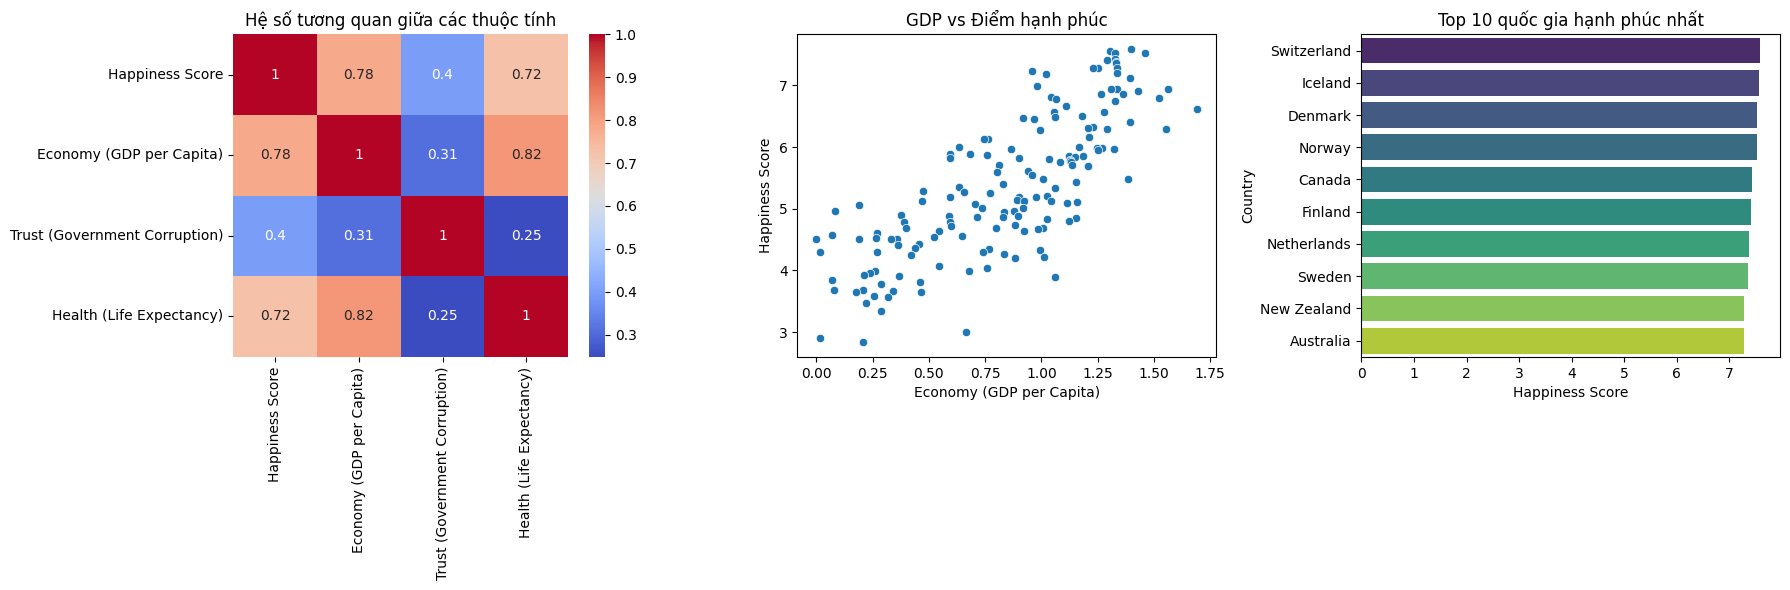

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = '/kaggle/input/world-happiness'

df = pd.read_csv(f'{path}/2015.csv')

#So sánh điểm hạnh phúc giữa các quốc gia và khu vực.

print('Diem hanh phuc theo quoc gia:')
print(df.pivot_table(index = 'Country', values = 'Happiness Score', aggfunc = 'mean'))
print('Diem hanh phuc theo khu vuc:')
print(df.pivot_table(index = 'Region', values = 'Happiness Score', aggfunc = 'mean'))

#Tính trung bình, trung vị, phương sai và độ lệch chuẩn bằng NumPy.

happiness_scoreARR = df['Happiness Score'].to_numpy()

print(f'Trung binh diem hanh phuc: f{np.mean(happiness_scoreARR):.2f}')
print(f'Trung vi diem hanh phuc: {np.median(happiness_scoreARR):.2f}')
print(f'Phuong sai diem hanh phuc: {np.var(happiness_scoreARR):.2f}')
print(f'Do lech chuan diem hanh phuc: {np.std(happiness_scoreARR):.2f}')

#Xếp hạng các quốc gia bằng Pandas.

df['Happiness Rank'] = df['Happiness Rank'].sort_values(ascending = True)
print('Top 10 quoc gia co diem hanh phuc cao nhat:')
print(df[['Happiness Rank','Country', 'Happiness Score']].head(10))
print('Top 10 quoc gia co diem hanh phuc thap nhat:')
print(df[['Happiness Rank','Country', 'Happiness Score']].tail(10))
#Phân tích tương quan giữa điểm hạnh phúc, GDP, hỗ trợ xã hội và tuổi thọ.

cols = ['Happiness Score', 'Economy (GDP per Capita)', 'Trust (Government Corruption)', 'Health (Life Expectancy)']
df_sub = df[cols].dropna()

print('He so tuong quan:')
print(df_sub.corr(method = 'pearson',numeric_only = True))
#Vẽ heatmap, scatterplot và biểu đồ xếp hạng.
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.heatmap(data = df_sub.corr(), annot = True, cmap = 'coolwarm', ax = axes[0])
axes[0].set_title('Hệ số tương quan giữa các thuộc tính')

sns.scatterplot(data = df, x = 'Economy (GDP per Capita)', y = 'Happiness Score', ax = axes[1])
axes[1].set_title('GDP vs Điểm hạnh phúc')

sns.barplot(data = df.head(10), x = 'Happiness Score', y = 'Country', ax = axes[2], palette = 'viridis')
axes[2].set_title('Top 10 quốc gia hạnh phúc nhất')

plt.tight_layout()
plt.show()

5 gia tri dau tien cua du lieu:
   OBJECTID FIRE_NAME  FIRE_YEAR  DISCOVERY_DATE  DISCOVERY_DOY  \
0         1  FOUNTAIN       2005       2453403.5             33   
1         2    PIGEON       2004       2453137.5            133   
2         3     SLACK       2004       2453156.5            152   
3         4      DEER       2004       2453184.5            180   
4         5  STEVENOT       2004       2453184.5            180   

  STAT_CAUSE_DESCR  FIRE_SIZE STATE  
0    Miscellaneous       0.10    CA  
1        Lightning       0.25    CA  
2   Debris Burning       0.10    CA  
3        Lightning       0.10    CA  
4        Lightning       0.10    CA  
Kieu du lieu:
OBJECTID              int64
FIRE_NAME            object
FIRE_YEAR             int64
DISCOVERY_DATE      float64
DISCOVERY_DOY         int64
STAT_CAUSE_DESCR     object
FIRE_SIZE           float64
STATE                object
dtype: object
Cac vu chay tu nam 2000:
                         FIRE_NAME  FIRE_YEAR   STAT_CAUSE_D

/tmp/ipykernel_1828/1686693821.py:108: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_states.values, y=top_states.index, ax=axes[0, 1], palette='Oranges_r')
/tmp/ipykernel_1828/1686693821.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=causes_summary['count'].values, y=causes_summary.index, ax=axes[1, 0], palette='YlOrRd_r')


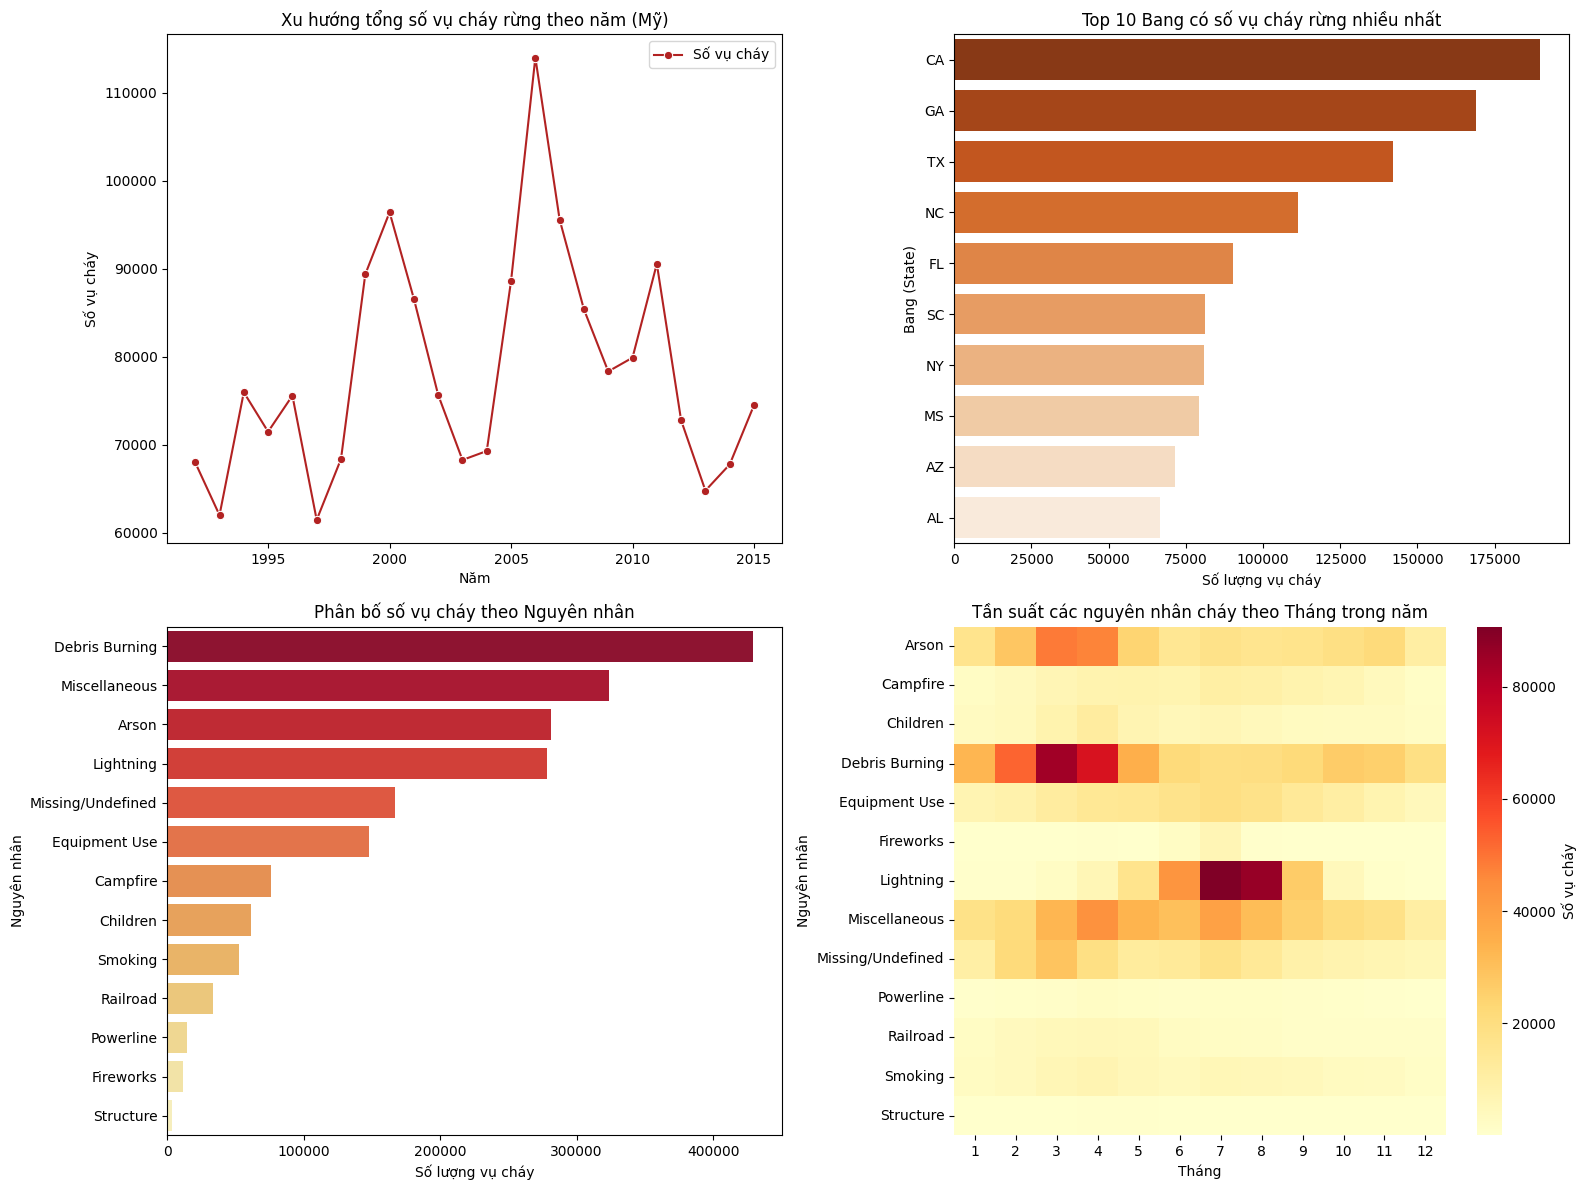

In [23]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

db_path = '/kaggle/input/188-million-us-wildfires/FPA_FOD_20170508.sqlite'

# Mở kết nối và đọc các cột cần thiết từ bảng Fires
query = """
SELECT
    OBJECTID,
    FIRE_NAME,
    FIRE_YEAR,
    DISCOVERY_DATE,
    DISCOVERY_DOY,
    STAT_CAUSE_DESCR,
    FIRE_SIZE,
    STATE
FROM Fires
"""

with sqlite3.connect(db_path) as conn:
    df = pd.read_sql_query(query, conn)

#Đọc và kiểm tra dữ liệu theo từng cột.
print('5 gia tri dau tien cua du lieu:')
print(df.head(5))
print('Kieu du lieu:')
print(df.dtypes)

#Lọc các vụ cháy theo năm, bang và nguyên nhân.

print('Cac vu chay tu nam 2000:')
print(df[df['FIRE_YEAR'] >= 2000][['FIRE_NAME', 'FIRE_YEAR', 'STAT_CAUSE_DESCR']])
print('Cac vu chay tu bang California:')
print(df[df['STATE'] == 'CA'][['FIRE_NAME', 'FIRE_YEAR', 'STAT_CAUSE_DESCR']])
print('Cac vu chay do sam set:')
print(df[df['STAT_CAUSE_DESCR'] == 'Lightning'][['FIRE_NAME', 'FIRE_YEAR', 'STAT_CAUSE_DESCR']])

#Xử lý ngày tháng, giá trị thiếu và dữ liệu trùng lặp.

df['DISCOVERY_DATE'] = pd.to_datetime(df['DISCOVERY_DATE'], unit = 'D', origin = 'julian')
df['DISCOVERY_MONTH'] = df['DISCOVERY_DATE'].dt.month


print('Tong so gia tri trung lap:')
print(df.duplicated().sum())
print('Du lieu trung lap:')
print(df[df.duplicated(keep = False)])
print('Tong so gia tri thieu:')
print(df.isnull().sum())
df['FIRE_NAME'] = df['FIRE_NAME'].fillna('Unknown')


#Dùng NumPy thực hiện các phép tính thống kê; trực quan hóa bằng Matplotlib/Seaborn.

fire_sizes_np = df['FIRE_SIZE'].to_numpy()

# Dùng NumPy thực hiện các phép tính thống kê
total_fires = len(fire_sizes_np)
total_acres = np.sum(fire_sizes_np)
mean_acres = np.mean(fire_sizes_np)
median_acres = np.median(fire_sizes_np)
std_acres = np.std(fire_sizes_np)
max_acres = np.max(fire_sizes_np)

print(f"Thống kê các vụ cháy tại Bang CA (2000 - 2015):")
print(f" - Tổng số vụ cháy: {total_fires:,} vụ")
print(f" - Tổng diện tích bị ảnh hưởng: {total_acres:,.2f} acres")
print(f" - Diện tích trung bình/vụ (Mean): {mean_acres:.2f} acres")
print(f" - Trung vị diện tích (Median): {median_acres:.2f} acres")
print(f" - Độ lệch chuẩn (Std): {std_acres:.2f}")
print(f" - Vụ cháy lớn nhất (Max): {max_acres:,.2f} acres")


# Tổng số vụ cháy và diện tích thiệt hại theo Năm trên toàn quốc
yearly_summary = df.groupby('FIRE_YEAR').agg(
    total_fires=('OBJECTID', 'count'),
    total_area=('FIRE_SIZE', 'sum')
).reset_index()

# Top 10 bang có số vụ cháy lớn nhất
top_states = df['STATE'].value_counts().head(10)

# Nguyên nhân gây cháy phổ biến nhất
causes_summary = df.groupby('STAT_CAUSE_DESCR').agg(
    count=('OBJECTID', 'count'),
    total_area=('FIRE_SIZE', 'sum')
).sort_values(by='count', ascending=False)

print("\n--- TOP 5 NGUYÊN NHÂN CHÁY RỪNG HÀNG ĐẦU ---")
print(causes_summary.head())


# ==========================================
# 5. TRỰC QUAN HÓA DỮ LIỆU (MATPLOTLIB & SEABORN)
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Subplot 1: Xu hướng số vụ cháy và diện tích thiệt hại theo năm (Lineplot)
sns.lineplot(data=yearly_summary, x='FIRE_YEAR', y='total_fires', ax=axes[0, 0], color='firebrick', marker='o', label='Số vụ cháy')
axes[0, 0].set_title('Xu hướng tổng số vụ cháy rừng theo năm (Mỹ)', fontsize=12)
axes[0, 0].set_xlabel('Năm')
axes[0, 0].set_ylabel('Số vụ cháy')

# Subplot 2: Top 10 Bang có số vụ cháy cao nhất (Barplot)
sns.barplot(x=top_states.values, y=top_states.index, ax=axes[0, 1], palette='Oranges_r')
axes[0, 1].set_title('Top 10 Bang có số vụ cháy rừng nhiều nhất', fontsize=12)
axes[0, 1].set_xlabel('Số lượng vụ cháy')
axes[0, 1].set_ylabel('Bang (State)')

# Subplot 3: Phân bố số vụ cháy theo các nguyên nhân (Barplot)
sns.barplot(x=causes_summary['count'].values, y=causes_summary.index, ax=axes[1, 0], palette='YlOrRd_r')
axes[1, 0].set_title('Phân bố số vụ cháy theo Nguyên nhân', fontsize=12)
axes[1, 0].set_xlabel('Số lượng vụ cháy')
axes[1, 0].set_ylabel('Nguyên nhân')

# Subplot 4: Biểu đồ nhiệt (Heatmap) - Số vụ cháy theo Tháng và Nguyên nhân
monthly_cause_matrix = df.groupby(['STAT_CAUSE_DESCR', 'DISCOVERY_MONTH']).size().unstack(fill_value=0)
sns.heatmap(monthly_cause_matrix, ax=axes[1, 1], cmap='YlOrRd', fmt='d', cbar_kws={'label': 'Số vụ cháy'})
axes[1, 1].set_title('Tần suất các nguyên nhân cháy theo Tháng trong năm', fontsize=12)
axes[1, 1].set_xlabel('Tháng')
axes[1, 1].set_ylabel('Nguyên nhân')

plt.tight_layout()
plt.show()